# 21 · Generative Models — Autoencoders, VAEs, GANs and Diffusion

Every model so far was **discriminative**: given x, predict y. A **generative** model learns the distribution of the data itself, p(x), so it can **create new examples**: images, text (notebook 17's GPT is one), audio, molecules. It can also score how *typical* an example is, which is useful for anomaly detection.

**What you'll learn**
1. Generative vs discriminative; density estimation with **KDE** and **Gaussian mixtures** — 🐍 → 🔢 → 📦
2. **Autoencoders:** compress and reconstruct; denoising; why a plain autoencoder is a poor generator
3. **Variational autoencoders (VAEs):** a smooth latent space, the **reparameterisation trick**, the **ELBO**
4. **GANs:** a generator and a discriminator in a game; **mode collapse**
5. **Diffusion models** (the engine behind Stable Diffusion, DALL·E, Sora) — a DDPM built from scratch
6. How to evaluate generative models, and the modern landscape

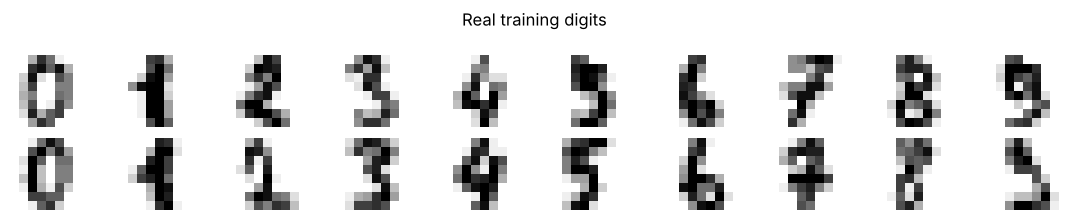

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math, time
import torch
from torch import nn
import torch.nn.functional as F
plt.rcParams["figure.figsize"] = (5.5, 3.6)
plt.rcParams["axes.grid"] = True; plt.rcParams["grid.alpha"] = 0.3
rng = np.random.default_rng(0); torch.manual_seed(0)

from sklearn.datasets import load_digits, make_moons
digits = load_digits(); X_dig = (digits.data / 16.0).astype(np.float32); y_dig = digits.target       # 1,797 images of 8×8 = 64 pixels

def show_digits(imgs, title="", n_cols=10, size=1.1):
    imgs = np.asarray(imgs); n_rows = math.ceil(len(imgs) / n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * size, n_rows * size))
    for ax, im in zip(np.atleast_1d(axes).ravel(), imgs): ax.imshow(im.reshape(8, 8), cmap="gray_r", vmin=0, vmax=1)
    for ax in np.atleast_1d(axes).ravel(): ax.axis("off")
    plt.suptitle(title); plt.tight_layout(); plt.show()

show_digits(X_dig[:20], "Real training digits")

## 1. Generative vs discriminative

| | Discriminative | Generative |
|---|---|---|
| Learns | p(y \| x) — the boundary between classes | p(x) (or p(x, y)) — what the data looks like |
| Examples | logistic regression, SVM, most classifiers | Naive Bayes, GMMs, VAEs, GANs, diffusion, GPT |
| Can create new data? | no | **yes** |

The hard part: data like images lives in a huge space (64 dimensions even for these tiny digits; millions for photos), but real examples occupy only a tiny, curved region of it (a "manifold"). Random pixels almost never look like a digit.

## 2. Classical density estimation

### Kernel density estimation (KDE)
Put a small Gaussian "bump" on every training point and add them up:
$$ \hat p(x) = \frac{1}{n}\sum_{i=1}^n \mathcal{N}(x;\, x_i,\, h^2 I) $$
The **bandwidth** h controls smoothness. To *sample*: pick a random training point and add Gaussian noise of size h. Simple and accurate in low dimensions — but it memorises the data, and it fails in high dimensions (curse of dimensionality, notebook 04).

density at (0, 1): pure Python 0.5652 | NumPy 0.5652 | sklearn 0.5652


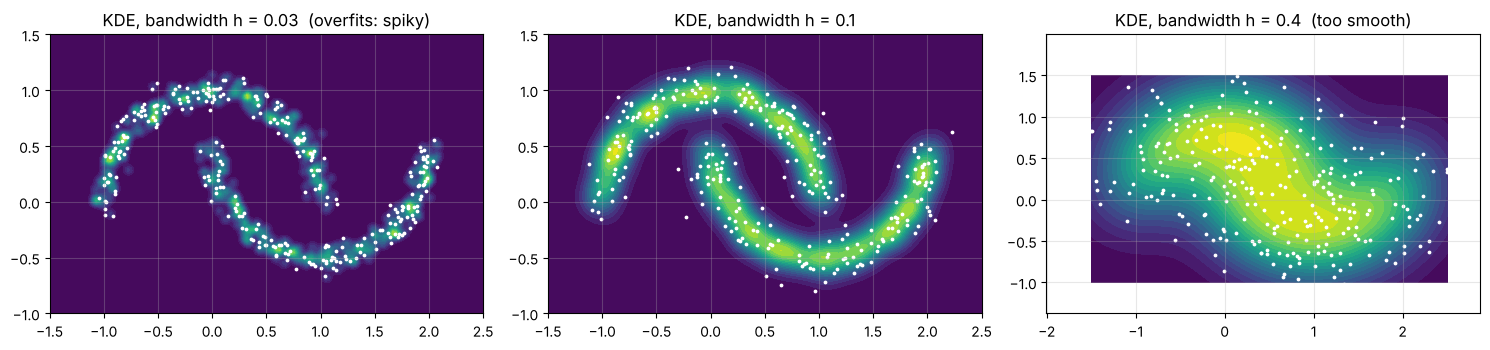

In [2]:
X_moons, _ = make_moons(500, noise=0.06, random_state=0)

# 🐍 Pure Python KDE density at one point
def kde_python(x, data, h):
    d = len(x); norm = (2 * math.pi * h * h) ** (-d / 2)
    return sum(norm * math.exp(-sum((a - b) ** 2 for a, b in zip(x, xi)) / (2 * h * h)) for xi in data) / len(data)

# 🔢 NumPy KDE on a whole grid at once
def kde_numpy(points, data, h):
    d2 = ((points[:, None, :] - data[None, :, :]) ** 2).sum(-1)
    return np.exp(-d2 / (2 * h * h)).mean(1) / (2 * math.pi * h * h)

from sklearn.neighbors import KernelDensity                                  # 📦
q = np.array([[0.0, 1.0]])                                                   # a point on the upper moon
print(f"density at (0, 1): pure Python {kde_python(q[0], X_moons.tolist(), 0.1):.4f} | NumPy {kde_numpy(q, X_moons, 0.1)[0]:.4f} | "
      f"sklearn {np.exp(KernelDensity(bandwidth=0.1).fit(X_moons).score_samples(q))[0]:.4f}")

gx, gy = np.meshgrid(np.linspace(-1.5, 2.5, 150), np.linspace(-1, 1.5, 120)); grid = np.c_[gx.ravel(), gy.ravel()]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, h in zip(axes, [0.03, 0.1, 0.4]):
    ax.contourf(gx, gy, kde_numpy(grid, X_moons, h).reshape(gx.shape), levels=20, cmap="viridis")
    samples = X_moons[rng.integers(0, 500, 300)] + rng.normal(0, h, (300, 2))      # sampling from a KDE
    ax.scatter(*samples.T, s=3, c="w"); ax.set_title(f"KDE, bandwidth h = {h}" + ["  (overfits: spiky)", "", "  (too smooth)"][[0.03, 0.1, 0.4].index(h)])
plt.tight_layout(); plt.show()

### Gaussian mixture models
A GMM (notebook 06) models p(x) as a weighted sum of a few Gaussians — compact, and easy to sample from: pick a component by its weight, then draw from that Gaussian. A classic trick for images: fit the GMM in a **PCA-reduced** space (where the data is less sparse), sample there, then map back to pixels.

PCA keeps 41 of 64 dimensions; GMM with 80 components


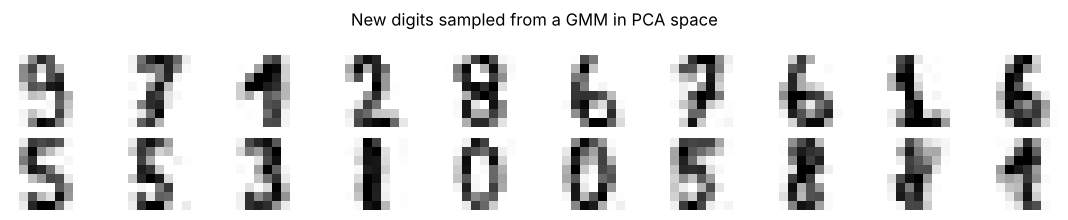

In [3]:
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
pca = PCA(0.99, whiten=False).fit(X_dig); Z = pca.transform(X_dig)
gmm = GaussianMixture(80, covariance_type="full", random_state=0).fit(Z)
new = pca.inverse_transform(gmm.sample(20)[0])
print(f"PCA keeps {pca.n_components_} of 64 dimensions; GMM with 80 components")
show_digits(np.clip(new, 0, 1), "New digits sampled from a GMM in PCA space")

Not bad for a classical model. Deep generative models replace "linear PCA + Gaussians" with **learned non-linear** mappings — and scale to photos.

## 3. Autoencoders

An **autoencoder** is a network trained to output its own input, through a narrow **bottleneck**:
```
x (64 pixels) → encoder → z (2 numbers: the "code" / latent vector) → decoder → x̂ (64 pixels)      loss = ‖x − x̂‖²
```
To reconstruct well through a 2-number bottleneck, the encoder must learn a compact description of a digit. Uses: compression, denoising, anomaly detection (high reconstruction error = unusual input), and as a building block for generative models. A *linear* autoencoder learns exactly the PCA subspace; non-linear ones go further.

trained in 4s


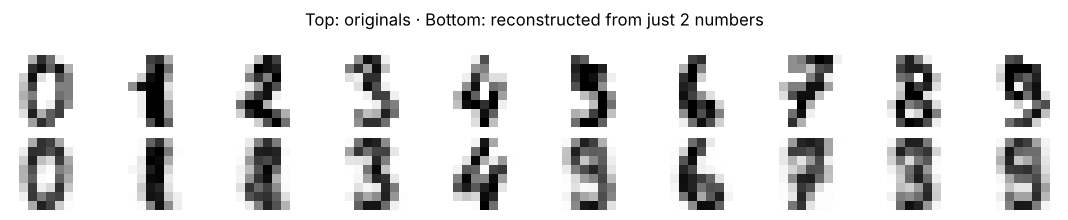

In [4]:
X_t = torch.tensor(X_dig)

class AutoEncoder(nn.Module):
    def __init__(self, d_latent=2):
        super().__init__()
        self.enc = nn.Sequential(nn.Linear(64, 128), nn.ReLU(), nn.Linear(128, 64), nn.ReLU(), nn.Linear(64, d_latent))
        self.dec = nn.Sequential(nn.Linear(d_latent, 64), nn.ReLU(), nn.Linear(64, 128), nn.ReLU(), nn.Linear(128, 64), nn.Sigmoid())
    def forward(self, x): return self.dec(self.enc(x))

def train(model, loss_fn, epochs=150, lr=2e-3, batch=128, data=X_t):
    opt = torch.optim.Adam(model.parameters(), lr=lr); hist = []
    for _ in range(epochs):
        perm = torch.randperm(len(data)); tot = 0
        for s in range(0, len(data), batch):
            xb = data[perm[s:s + batch]]; loss = loss_fn(model, xb)
            opt.zero_grad(); loss.backward(); opt.step(); tot += loss.item() * len(xb)
        hist.append(tot / len(data))
    return hist

torch.manual_seed(0); ae = AutoEncoder(2)
t0 = time.perf_counter(); train(ae, lambda m, x: F.mse_loss(m(x), x)); print(f"trained in {time.perf_counter() - t0:.0f}s")
with torch.no_grad(): z_ae = ae.enc(X_t).numpy(); recon = ae(X_t[:10]).numpy()
show_digits(np.vstack([X_dig[:10], recon]), "Top: originals · Bottom: reconstructed from just 2 numbers")

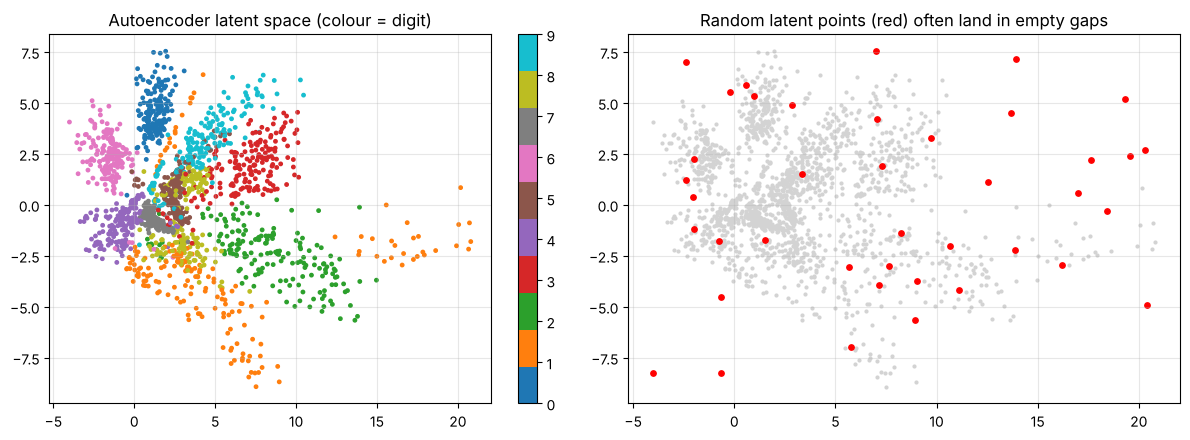

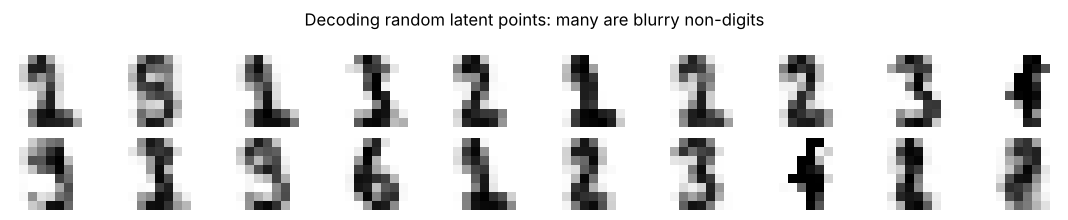

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sc = ax[0].scatter(*z_ae.T, c=y_dig, cmap="tab10", s=6); plt.colorbar(sc, ax=ax[0]); ax[0].set_title("Autoencoder latent space (colour = digit)")
# Try to GENERATE by decoding random points in the latent box
zr = rng.uniform(z_ae.min(0), z_ae.max(0), (40, 2)).astype(np.float32)
with torch.no_grad(): gen = ae.dec(torch.tensor(zr)).numpy()
ax[1].scatter(*z_ae.T, c="lightgray", s=4); ax[1].scatter(*zr.T, c="r", s=15); ax[1].set_title("Random latent points (red) often land in empty gaps")
plt.tight_layout(); plt.show()
show_digits(gen[:20], "Decoding random latent points: many are blurry non-digits")

The autoencoder organises digits into clusters, but its latent space has **gaps and irregular shapes** — nothing forced it to be smooth or filled in. Decoding a random point often gives garbage. To *generate*, we need a latent space we can sample from. Enter the VAE.

## 4. Variational autoencoders (VAEs)

Two changes make the latent space generative:
1. The encoder outputs a **distribution**, not a point: a mean μ(x) and a standard deviation σ(x). We sample $z = \mu + \sigma \odot \varepsilon$, $\varepsilon \sim \mathcal{N}(0, I)$.
2. A **KL-divergence penalty** pulls each of those distributions toward the standard normal $\mathcal{N}(0, I)$. This packs the codes into a smooth, gap-free ball — so at generation time we can simply sample $z \sim \mathcal{N}(0, I)$ and decode.

The loss is the negative **ELBO** (evidence lower bound) on the data log-likelihood:
$$ \mathcal{L} = \underbrace{\mathbb{E}\big[-\log p(x \mid z)\big]}_{\text{reconstruction}} + \underbrace{\text{KL}\big(\mathcal{N}(\mu, \sigma^2)\,\|\,\mathcal{N}(0, 1)\big)}_{\text{stay close to the prior}}, \qquad \text{KL} = \tfrac{1}{2}\sum_j\big(\mu_j^2 + \sigma_j^2 - \log\sigma_j^2 - 1\big) $$

**The reparameterisation trick:** you can't backpropagate through "draw a random sample". Writing $z = \mu + \sigma\varepsilon$ moves the randomness into ε (no parameters), so gradients flow to μ and σ.

In [6]:
# 🔢 Check the closed-form KL against a Monte Carlo estimate
mu_, sigma_ = 0.8, 0.5
kl_closed = 0.5 * (mu_ ** 2 + sigma_ ** 2 - np.log(sigma_ ** 2) - 1)
z_s = rng.normal(mu_, sigma_, 1_000_000)
log_q = -0.5 * ((z_s - mu_) / sigma_) ** 2 - np.log(sigma_ * np.sqrt(2 * np.pi)); log_p = -0.5 * z_s ** 2 - np.log(np.sqrt(2 * np.pi))
print(f"KL(N({mu_},{sigma_}²) ‖ N(0,1)): closed form {kl_closed:.4f} | Monte Carlo {np.mean(log_q - log_p):.4f}")

KL(N(0.8,0.5²) ‖ N(0,1)): closed form 0.6381 | Monte Carlo 0.6380


trained in 5s; final loss 24.1


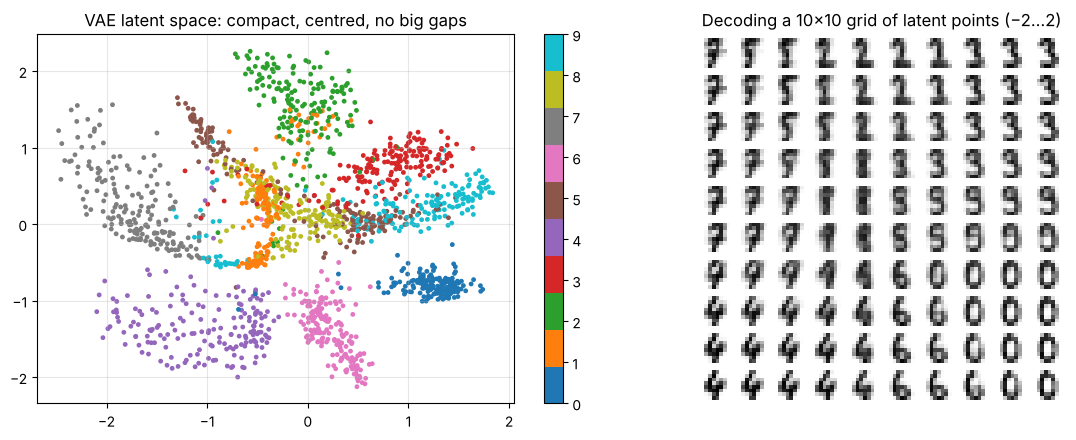

In [7]:
class VAE(nn.Module):
    def __init__(self, d_latent=2):
        super().__init__()
        self.enc = nn.Sequential(nn.Linear(64, 128), nn.ReLU(), nn.Linear(128, 64), nn.ReLU())
        self.mu, self.logvar = nn.Linear(64, d_latent), nn.Linear(64, d_latent)
        self.dec = nn.Sequential(nn.Linear(d_latent, 64), nn.ReLU(), nn.Linear(64, 128), nn.ReLU(), nn.Linear(128, 64))   # outputs logits
    def forward(self, x):
        h = self.enc(x); mu, logvar = self.mu(h), self.logvar(h)
        z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)          # reparameterisation trick
        return self.dec(z), mu, logvar

def vae_loss(model, x, beta=1.0):
    logits, mu, logvar = model(x)
    recon = F.binary_cross_entropy_with_logits(logits, x, reduction="sum") / len(x)      # −log p(x|z), pixels as Bernoulli
    kl = 0.5 * (mu.pow(2) + logvar.exp() - logvar - 1).sum() / len(x)
    return recon + beta * kl

torch.manual_seed(0); vae = VAE(2)
t0 = time.perf_counter(); hist = train(vae, vae_loss, epochs=200); print(f"trained in {time.perf_counter() - t0:.0f}s; final loss {hist[-1]:.1f}")
with torch.no_grad(): z_vae = vae.mu(vae.enc(X_t)).numpy()

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sc = ax[0].scatter(*z_vae.T, c=y_dig, cmap="tab10", s=6); plt.colorbar(sc, ax=ax[0]); ax[0].set_title("VAE latent space: compact, centred, no big gaps")
# Decode a regular grid of latent points → a "map" of what the model has learned
g = np.linspace(-2, 2, 10); grid_z = np.array([[a, b] for b in g[::-1] for a in g], np.float32)
with torch.no_grad(): tiles = torch.sigmoid(vae.dec(torch.tensor(grid_z))).numpy().reshape(10, 10, 8, 8)
tiles = np.pad(tiles, ((0, 0), (0, 0), (1, 1), (1, 1)))                      # 1-pixel white border around each tile
ax[1].imshow(tiles.transpose(0, 2, 1, 3).reshape(10 * 10, 10 * 10), cmap="gray_r"); ax[1].axis("off")
ax[1].set_title("Decoding a 10×10 grid of latent points (−2…2)")
plt.tight_layout(); plt.show()

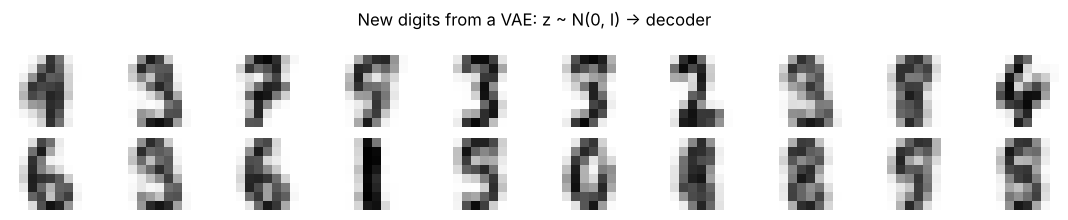

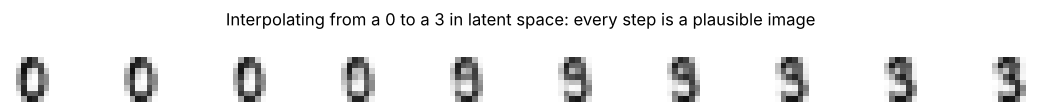

In [8]:
# Generation: sample z ~ N(0, I) and decode. Use a slightly bigger latent space for sharper samples.
torch.manual_seed(0); vae8 = VAE(8); train(vae8, vae_loss, epochs=200)
with torch.no_grad(): samples = torch.sigmoid(vae8.dec(torch.randn(20, 8))).numpy()
show_digits(samples, "New digits from a VAE: z ~ N(0, I) → decoder")

# Interpolation: walk in a straight line between two digits' codes
with torch.no_grad():
    za, zb = vae8.mu(vae8.enc(X_t[[0]])), vae8.mu(vae8.enc(X_t[[3]]))
    path = torch.sigmoid(vae8.dec(torch.cat([za + t * (zb - za) for t in np.linspace(0, 1, 10)]))).numpy()
show_digits(path, "Interpolating from a 0 to a 3 in latent space: every step is a plausible image")

VAEs give a smooth, structured latent space and an actual likelihood bound — but their samples tend to be **blurry**: the reconstruction loss averages over uncertainty. (**β-VAEs** weight the KL term to trade sharpness for more disentangled latents; **VQ-VAEs** use a discrete codebook and power many image and audio models.)

## 5. Generative adversarial networks (GANs)

A GAN (Goodfellow et al., 2014) is a **game between two networks**:
- the **generator** G turns random noise z into fake samples;
- the **discriminator** D tries to tell real samples from fakes.

$$ \min_G \max_D \; \mathbb{E}_{x \sim \text{data}}[\log D(x)] + \mathbb{E}_z[\log(1 - D(G(z)))] $$
D is a classifier trained on real-vs-fake; G is trained to *fool* D (in practice, to maximise log D(G(z))). At equilibrium, G's samples are indistinguishable from real data. No explicit likelihood, no blur — GANs famously produce sharp images (StyleGAN faces) — but training is **unstable**, and GANs are prone to **mode collapse**: the generator finds a few outputs that fool D and ignores the rest of the data's variety.

We'll train on a 2-D "ring of 8 Gaussians" — easy to visualise, and a classic test for mode collapse.

trained in 9s (random seed 1 — the next cell shows how much seeds matter)


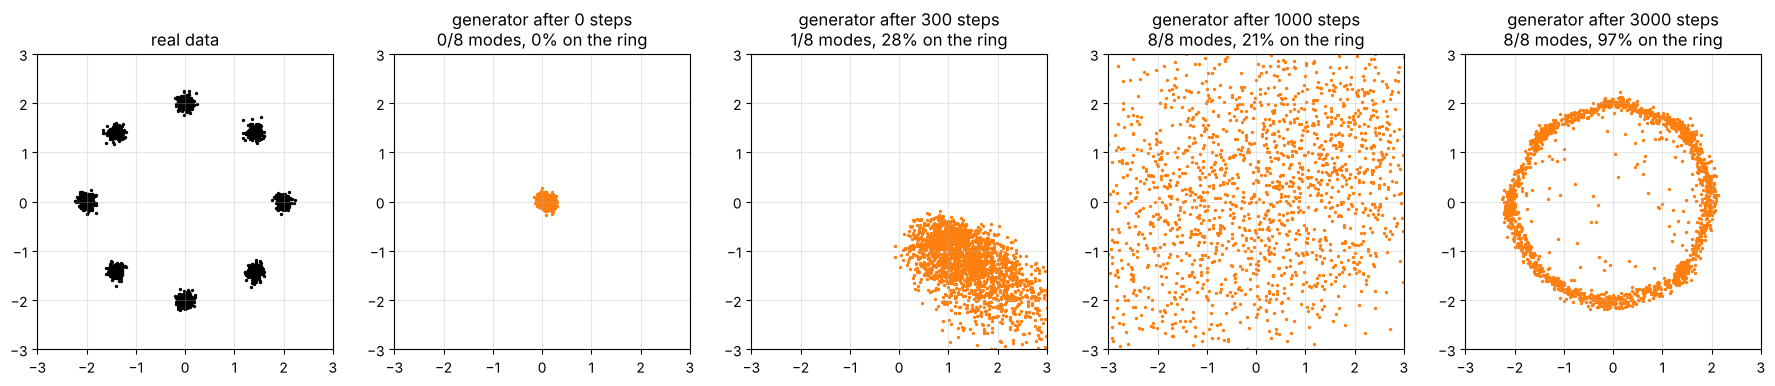

In [9]:
def ring_data(n, seed=0):
    r = np.random.default_rng(seed); k = r.integers(0, 8, n); ang = 2 * np.pi * k / 8
    return (np.c_[np.cos(ang), np.sin(ang)] * 2 + r.normal(0, 0.08, (n, 2))).astype(np.float32)
real = torch.tensor(ring_data(20_000))

def make_gan(d_noise=8, d_hidden=128):
    G = nn.Sequential(nn.Linear(d_noise, d_hidden), nn.ReLU(), nn.Linear(d_hidden, d_hidden), nn.ReLU(), nn.Linear(d_hidden, 2))
    D = nn.Sequential(nn.Linear(2, d_hidden), nn.LeakyReLU(0.2), nn.Linear(d_hidden, d_hidden), nn.LeakyReLU(0.2), nn.Linear(d_hidden, 1))
    return G, D

def train_gan(steps=3000, batch=256, d_noise=8, lr=2e-4, snapshots=(0, 300, 1000, 3000), seed=0):
    torch.manual_seed(seed); G, D = make_gan(d_noise)
    opt_g, opt_d = torch.optim.Adam(G.parameters(), lr, betas=(0.5, 0.999)), torch.optim.Adam(D.parameters(), lr, betas=(0.5, 0.999))
    snaps = {}; fixed_z = torch.randn(2000, d_noise)
    for step in range(steps + 1):
        if step in snapshots:
            with torch.no_grad(): snaps[step] = G(fixed_z).numpy()
        if step == steps: break
        xr = real[torch.randint(0, len(real), (batch,))]; xf = G(torch.randn(batch, d_noise))
        # 1) discriminator step: real → 1, fake → 0
        loss_d = F.binary_cross_entropy_with_logits(D(xr), torch.ones(batch, 1)) + F.binary_cross_entropy_with_logits(D(xf.detach()), torch.zeros(batch, 1))
        opt_d.zero_grad(); loss_d.backward(); opt_d.step()
        # 2) generator step: make D say "real" for fakes
        loss_g = F.binary_cross_entropy_with_logits(D(xf), torch.ones(batch, 1))
        opt_g.zero_grad(); loss_g.backward(); opt_g.step()
    return G, snaps

def modes_covered(samples):
    ang = np.arctan2(samples[:, 1], samples[:, 0]); k = np.round(ang / (2 * np.pi / 8)) % 8
    near = np.abs(np.linalg.norm(samples, axis=1) - 2) < 0.3
    counts = np.bincount(k[near].astype(int), minlength=8)
    return int((counts > 0.02 * len(samples)).sum()), near.mean()

t0 = time.perf_counter(); G, snaps = train_gan(seed=1); print(f"trained in {time.perf_counter() - t0:.0f}s (random seed 1 — the next cell shows how much seeds matter)")
fig, axes = plt.subplots(1, 5, figsize=(18, 3.6))
axes[0].scatter(*real[:2000].numpy().T, s=2, c="k"); axes[0].set_title("real data")
for ax, (step, s) in zip(axes[1:], snaps.items()):
    m, q_ = modes_covered(s); ax.scatter(*s.T, s=2, c="C1"); ax.set_title(f"generator after {step} steps\n{m}/8 modes, {q_:.0%} on the ring")
for ax in axes: ax.set_xlim(-3, 3); ax.set_ylim(-3, 3); ax.set_aspect("equal")
plt.tight_layout(); plt.show()

In [10]:
# GAN training is fragile: same code, different random seeds
for seed in range(4):
    _, sn = train_gan(seed=seed, snapshots=(3000,))
    m, q_ = modes_covered(sn[3000]); print(f"seed {seed}: generator covers {m}/8 modes, {q_:.0%} of samples land on the ring")

seed 0: generator covers 8/8 modes, 56% of samples land on the ring


seed 1: generator covers 8/8 modes, 97% of samples land on the ring


seed 2: generator covers 2/8 modes, 41% of samples land on the ring


seed 3: generator covers 8/8 modes, 98% of samples land on the ring


Depending on the seed, a GAN may cover all modes or collapse onto a subset (seed 2 found only 2 of the 8 clusters). Even the good runs aren't perfect. Look at the step-3000 picture: the generator learned the *ring*, but it smears samples **between** the eight clusters instead of producing eight tight blobs. My simple "modes covered / on the ring" score doesn't catch that, which is a reminder that every generative metric is partial. Stabilisation tricks (Wasserstein loss with gradient penalty, spectral normalisation, two-time-scale learning rates, minibatch discrimination) are a big part of GAN practice. The difficulty of training GANs at scale is one reason the field moved to diffusion.

## 6. Diffusion models

**Idea:** destroying data is easy — keep adding a little Gaussian noise until only noise is left. Learn to **reverse** that process one small step at a time. Then start from pure noise and denoise your way to a new sample.

**Forward process** (fixed, no learning): over T steps, with a noise schedule $\beta_1 < \dots < \beta_T$,
$$ q(x_t \mid x_0) = \mathcal{N}\big(\sqrt{\bar\alpha_t}\,x_0,\; (1-\bar\alpha_t) I\big), \qquad \bar\alpha_t = \prod_{s \le t}(1 - \beta_s) $$
so we can jump straight to any noise level: $x_t = \sqrt{\bar\alpha_t}\,x_0 + \sqrt{1-\bar\alpha_t}\,\varepsilon$.

**Training (DDPM, Ho et al. 2020):** pick a random t, noise a real sample, and train a network $\varepsilon_\theta(x_t, t)$ to **predict the noise** that was added — plain MSE regression:
$$ \mathcal{L} = \mathbb{E}_{x_0, t, \varepsilon}\,\big\|\varepsilon - \varepsilon_\theta(\sqrt{\bar\alpha_t}x_0 + \sqrt{1-\bar\alpha_t}\varepsilon,\; t)\big\|^2 $$
**Sampling:** start from $x_T \sim \mathcal{N}(0, I)$ and repeatedly remove the predicted noise (plus a little fresh noise):
$$ x_{t-1} = \frac{1}{\sqrt{1-\beta_t}}\Big(x_t - \frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\,\varepsilon_\theta(x_t, t)\Big) + \sqrt{\beta_t}\,z $$
Stable training (just regression!), excellent coverage of all modes, and state-of-the-art quality — at the cost of many network evaluations per sample.

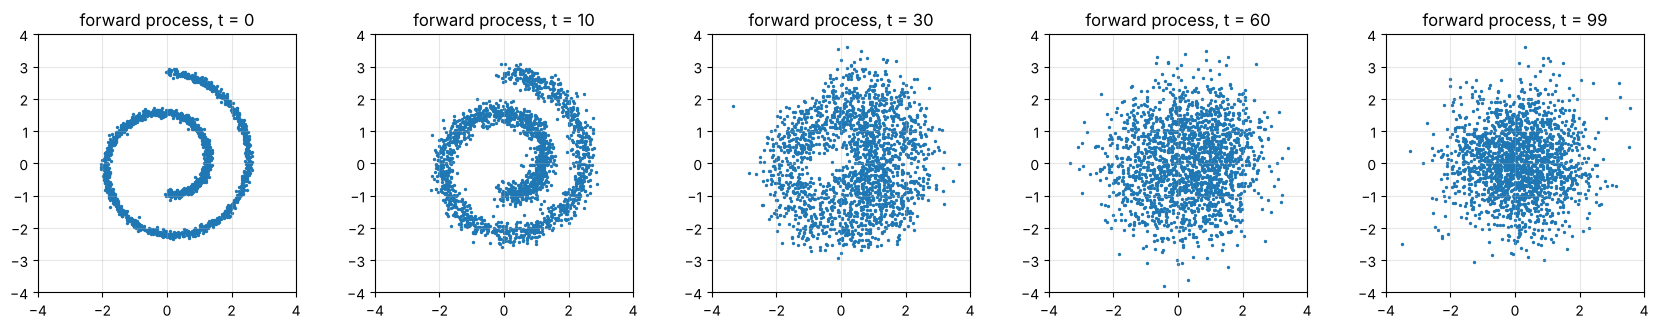

In [11]:
# A 2-D "swiss roll" dataset
from sklearn.datasets import make_swiss_roll
sr = make_swiss_roll(20_000, noise=0.3, random_state=0)[0][:, [0, 2]] / 5.0
data = torch.tensor(sr, dtype=torch.float32)

T = 100
betas = torch.linspace(1e-4, 0.05, T)
alphas = 1 - betas; alpha_bar = torch.cumprod(alphas, 0)

# 🔢 Forward process: jump to any noise level in one step
fig, axes = plt.subplots(1, 5, figsize=(17, 3.2))
for ax, t in zip(axes, [0, 10, 30, 60, 99]):
    eps = torch.randn_like(data[:2000])
    xt = alpha_bar[t].sqrt() * data[:2000] + (1 - alpha_bar[t]).sqrt() * eps
    ax.scatter(*xt.numpy().T, s=2); ax.set_title(f"forward process, t = {t}"); ax.set_xlim(-4, 4); ax.set_ylim(-4, 4); ax.set_aspect("equal")
plt.tight_layout(); plt.show()

trained in 8s


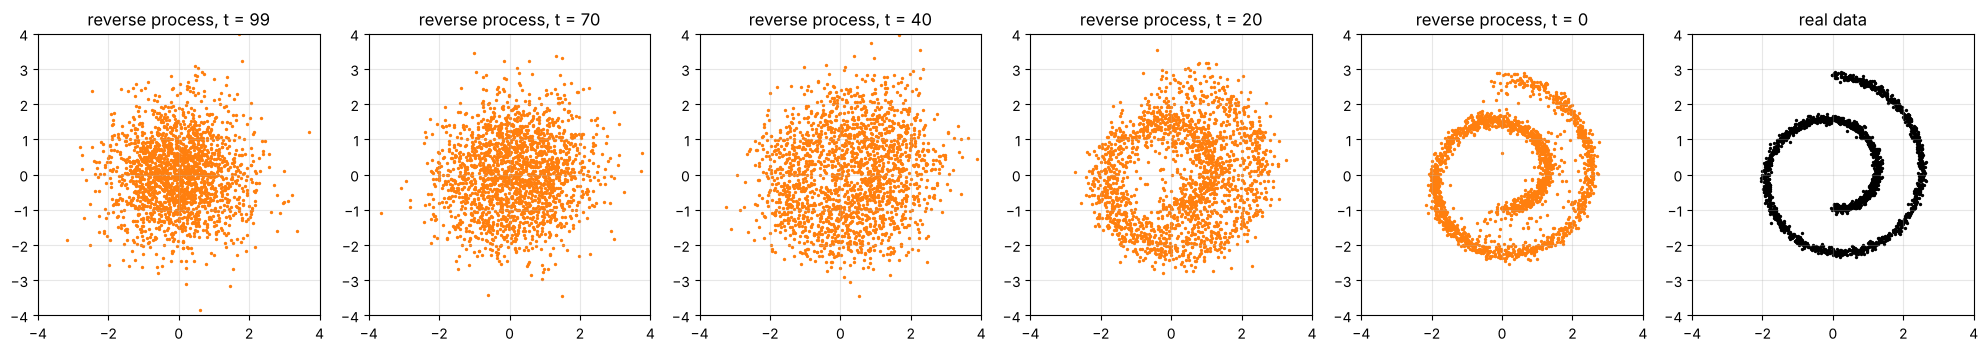

In [12]:
class Denoiser(nn.Module):
    """ε_θ(x_t, t): an MLP that sees the noisy point and a sinusoidal embedding of the time step."""
    def __init__(self, d=128):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(2 + 16, d), nn.SiLU(), nn.Linear(d, d), nn.SiLU(), nn.Linear(d, d), nn.SiLU(), nn.Linear(d, 2))
    def forward(self, x, t):
        freqs = torch.exp(torch.linspace(0, math.log(100), 8))
        te = torch.cat([torch.sin(t[:, None] * freqs / T * 10), torch.cos(t[:, None] * freqs / T * 10)], 1)   # like positional encodings
        return self.net(torch.cat([x, te], 1))

torch.manual_seed(0); eps_model = Denoiser(); opt = torch.optim.Adam(eps_model.parameters(), lr=2e-3)
losses = []; t0 = time.perf_counter()
for step in range(4000):
    x0 = data[torch.randint(0, len(data), (512,))]
    t = torch.randint(0, T, (512,)); eps = torch.randn_like(x0)
    xt = alpha_bar[t].sqrt()[:, None] * x0 + (1 - alpha_bar[t]).sqrt()[:, None] * eps
    loss = F.mse_loss(eps_model(xt, t.float()), eps)                     # predict the noise
    opt.zero_grad(); loss.backward(); opt.step(); losses.append(loss.item())
print(f"trained in {time.perf_counter() - t0:.0f}s")

@torch.no_grad()
def sample(n=2000, keep=(99, 70, 40, 20, 0), seed=0):
    g = torch.Generator().manual_seed(seed)
    x = torch.randn(n, 2, generator=g); traj = {}
    for t in reversed(range(T)):
        eps_hat = eps_model(x, torch.full((n,), float(t)))
        x = (x - betas[t] / (1 - alpha_bar[t]).sqrt() * eps_hat) / alphas[t].sqrt()
        if t > 0: x = x + betas[t].sqrt() * torch.randn(n, 2, generator=g)
        if t in keep: traj[t] = x.numpy().copy()
    return traj

traj = sample()
fig, axes = plt.subplots(1, 6, figsize=(20, 3.3))
for ax, (t, pts) in zip(axes, traj.items()):
    ax.scatter(*pts.T, s=2, c="C1"); ax.set_title(f"reverse process, t = {t}")
axes[-1].scatter(*sr[:2000].T, s=2, c="k"); axes[-1].set_title("real data")
for ax in axes: ax.set_xlim(-4, 4); ax.set_ylim(-4, 4); ax.set_aspect("equal")
plt.tight_layout(); plt.show()

From pure noise, 100 small denoising steps sculpt the swiss roll. Real image models use the same recipe with:
- a **U-Net** or **transformer** denoiser instead of an MLP;
- **latent diffusion** — diffuse in a compressed VAE latent space rather than in pixels (Stable Diffusion);
- **conditioning** on text (via cross-attention to a text encoder) and **classifier-free guidance** to follow the prompt more strongly;
- **faster samplers** (DDIM, DPM-Solver), **consistency models** and **flow matching** to cut 1,000 steps down to a handful.

## 7. Evaluating generative models — and the landscape

Evaluating generators is hard: there's no single "correct" output.
- **Likelihood** (bits per dimension) — available for VAEs (a bound), autoregressive models and flows; not for GANs.
- **FID** (Fréchet Inception Distance) — compares statistics of real vs generated images in a pretrained network's feature space; lower is better. **Precision/recall** for generative models separate *quality* (samples look real) from *coverage* (all modes represented).
- **Human evaluation** and task-specific checks (e.g. does the generated molecule bind?).
- Always check for **memorisation** — a model that copies training images can score well and still be useless (or a privacy/copyright problem).

For our 2-D toys, a simple coverage-and-quality check:

In [13]:
def ring_score(s):
    m, q_ = modes_covered(s); return f"{m}/8 modes, {q_:.0%} on ring"
sn = snaps                                                                   # the seed-1 GAN trained above
kde_s = ring_data(2000, 1)[rng.integers(0, 2000, 2000)] + rng.normal(0, 0.05, (2000, 2))
print("ring of Gaussians — GAN:", ring_score(sn[3000]), "| KDE (memorises the training points):", ring_score(kde_s))

ring of Gaussians — GAN: 8/8 modes, 97% on ring | KDE (memorises the training points): 8/8 modes, 100% on ring


| Family | How it generates | Strengths | Weaknesses |
|---|---|---|---|
| **Autoregressive** (GPT, PixelCNN) | one token/pixel at a time, p(x) = ∏ p(xᵢ \| x₍<ᵢ₎) | exact likelihood; dominant for text | slow sequential sampling |
| **VAE** | decode z ~ N(0, I) | fast; smooth latent space; likelihood bound | blurry samples |
| **GAN** | G(z) in one pass | sharp; fast sampling | unstable training; mode collapse; no likelihood |
| **Normalising flows** | invertible transforms of noise | exact likelihood, exact inversion | constrained architectures |
| **Diffusion / flow matching** | iterative denoising | best image/audio/video quality; stable training; mode coverage | many steps per sample (improving fast) |

**Responsible use:** generative models can produce deepfakes, misinformation and copyrighted or private training content. Watermarking, provenance tracking, dataset governance and consent are part of building them.

## Key takeaways
- Generative models learn p(x) so they can sample new data; classical KDE/GMM work in low dimensions.
- Autoencoders compress through a bottleneck; their latent space isn't designed for sampling.
- VAEs = autoencoder + noise + KL to N(0, I) → smooth latent space; trained with the reparameterisation trick and the ELBO.
- GANs = generator vs discriminator; sharp but unstable, prone to mode collapse.
- Diffusion = learn to predict and remove noise step by step; simple MSE training, top quality — the basis of modern image/video generators.

## Exercises
1. Train a **denoising autoencoder**: add Gaussian noise to the inputs but compute the loss against the clean images. Show noisy → cleaned digits.
2. Use the 2-D autoencoder's **reconstruction error** to flag anomalies: which digits are reconstructed worst? Do they look unusual?
3. Train the VAE with β = 0.1 and β = 4. How do sample sharpness and the latent-space layout change?
4. Train the diffusion model with T = 20 instead of 100 (rescale β accordingly). How does sample quality change?

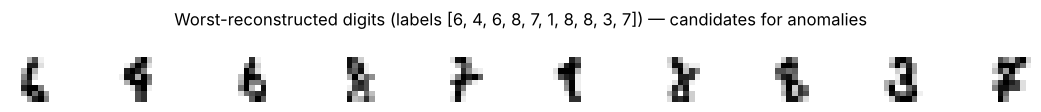

In [14]:
# Exercise 2 — solution
with torch.no_grad(): err = ((ae(X_t) - X_t) ** 2).mean(1).numpy()
worst = np.argsort(-err)[:10]
show_digits(X_dig[worst], f"Worst-reconstructed digits (labels {y_dig[worst].tolist()}) — candidates for anomalies")

**Next:** [22 · ML in Production](22_ml_in_production.ipynb) — getting models into the real world and keeping them healthy.

*Going deeper / interview prep:* `DL_Interview_Notes.md` Part 8 (autoencoders, VAEs, GANs, diffusion, and how the generative families compare), §9.2 (self-supervised learning) · `Probability_Statistics_Notes.md` §3.2 (maximum likelihood) · `Calculus_Notes.md` §10.4 (differentiating an expectation — the reparameterisation trick).